# Excepciones de VaR para TES

## Resumen
Evaluación descriptiva de excepciones de un proxy de retorno TES existente, no validación de un modelo institucional.

## Contexto y método
El conteo no prueba independencia ni calibración fuera de muestra por sí solo. La fuente representa una aproximación de rendimiento, sin posiciones reales ni precios ejecutables.

## Datos y preparación
Ejecutar desde la raíz del repositorio o la carpeta del proyecto. Requiere Python, pandas, matplotlib y Jupyter.

Fuente y metodología: [companion TES](../../../02-market-and-model-risk/backtesting-var-kupiec-christoffersen/README.md).

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True})

In [2]:
p=root/'03-financial-risk/02-market-and-model-risk/backtesting-var-kupiec-christoffersen/data/official/colombian_tes/rolling_backtest.csv'
df=pd.read_csv(p,parse_dates=['date']); df['exception']=df.exception.astype(str).str.lower().eq('true')
print('Archivo SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest())
print('Fechas:',df.date.min().date(),df.date.max().date())
t=df.groupby(['method','level']).agg(observaciones=('exception','size'),excepciones=('exception','sum'));t['tasa_observada']=t.excepciones/t.observaciones;t['tasa_nominal']=1-t.index.get_level_values('level');t.round(4)

Archivo SHA-256: a154a7f97de85676bc69d234da1824a9feac658641adfce5041cb7f300372f71
Fechas: 2019-01-02 2026-11-06


observaciones  excepciones  tasa_observada  tasa_nominal
method     level                                                          
gaussian   0.950           1913           91          0.0476         0.050
           0.975           1913           62          0.0324         0.025
           0.990           1913           38          0.0199         0.010
historical 0.950           1913          146          0.0763         0.050
           0.975           1913           77          0.0403         0.025
           0.990           1913           21          0.0110         0.010

## Resultados

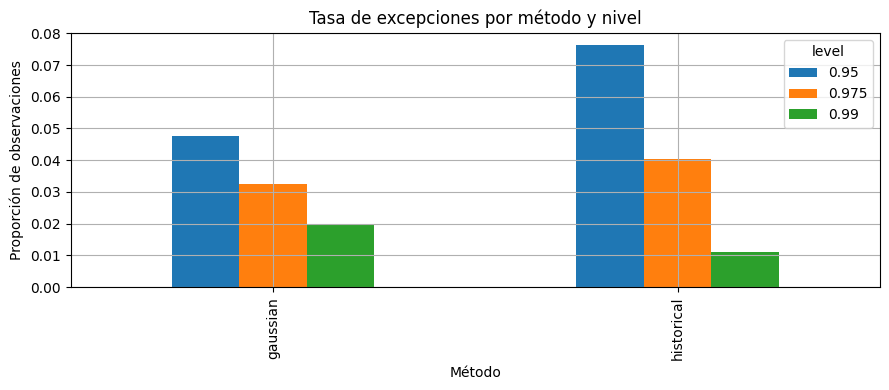

In [3]:
ax=t['tasa_observada'].unstack().plot.bar(title='Tasa de excepciones por método y nivel'); ax.set(xlabel='Método',ylabel='Proporción de observaciones'); plt.tight_layout();plt.show()

### Control de cobertura y consistencia
La tasa nominal es 1 menos el nivel de confianza. La brecha en puntos porcentuales describe el periodo observado; no es una prueba de independencia de excepciones ni sustituye un análisis fuera de muestra.

En el archivo revisado hay seis banderas positivas con pérdida y VaR iguales a la precisión publicada. La bandera pudo calcularse antes del redondeo; sin valores de mayor precisión no se puede reconstruir la comparación exacta.

In [4]:
keys=['date','method','level']
assert not df.duplicated(keys).any(), 'Fechas duplicadas para método y nivel'
assert df[['loss_return_proxy','var_return_proxy']].notna().all().all()
computed=df.loss_return_proxy > df.var_return_proxy
print('Discrepancias entre pérdida > VaR y bandera:',int((computed != df.exception).sum()))
t['brecha_pp']=100*(t.tasa_observada-t.tasa_nominal)
t[['observaciones','excepciones','tasa_observada','tasa_nominal','brecha_pp']].round(4)
print('Filas discrepantes:')
discrepancias=df.loc[computed != df.exception,['date','method','level','loss_return_proxy','var_return_proxy','exception']]
print(discrepancias.to_string(index=False))

Discrepancias entre pérdida > VaR y bandera: 6
Filas discrepantes:
      date     method  level  loss_return_proxy  var_return_proxy  exception
2020-09-08 historical  0.950             0.0072            0.0072       True
2021-08-09 historical  0.950             0.0088            0.0088       True
2022-03-25 historical  0.950             0.0104            0.0104       True
2022-09-05 historical  0.950             0.0136            0.0136       True
2022-12-05 historical  0.950             0.0144            0.0144       True
2025-12-29 historical  0.975             0.0224            0.0224       True


## Variante: probabilidad binomial de excepciones
Bajo la hipótesis de excepciones independientes y probabilidad constante $p=1-\alpha$, el número de excepciones en $N$ observaciones sigue una binomial. Se presentan el valor p bilateral exacto y su comparación con 5 % **sin corrección por pruebas múltiples**; son diagnósticos, no probabilidades de que el modelo sea correcto. Los seis empates a precisión publicada siguen abiertos. [Basilea MAR99](https://www.bis.org/committees/bcbs/basel-framework/standard/mar/99/inforce/2019-12-15/published/2019-12-15) describe los supuestos de cobertura e independencia. La metodología requiere `scipy` además de pandas y matplotlib.

In [5]:
from scipy.stats import binomtest
resultados=[]
for (metodo,nivel),fila in t.iterrows():
    N=int(fila.observaciones); k=int(fila.excepciones); p0=1-float(nivel)
    test=binomtest(k,N,p0,alternative='two-sided')
    resultados.append({'metodo':metodo,'nivel':nivel,'N':N,'k':k,'esperadas':N*p0,'p_valor_bilateral':test.pvalue})
tabla_binomial=pd.DataFrame(resultados)
tabla_binomial.round(5)

,metodo,nivel,N,k,esperadas,p_valor_bilateral
0,gaussian,0.950,1913,91,95.650,0.67467
1,gaussian,0.975,1913,62,47.825,0.04742
2,gaussian,0.990,1913,38,19.130,0.00012
3,historical,0.950,1913,146,95.650,0.00000
4,historical,0.975,1913,77,47.825,0.00007
5,historical,0.990,1913,21,19.130,0.64464


## Alcance y decisión
El conteo no prueba independencia ni calibración fuera de muestra por sí solo. La fuente representa una aproximación de rendimiento, sin posiciones reales ni precios ejecutables.

Fuente y metodología detalladas en el README y en el companion de origen. Este ejercicio no constituye validación independiente.